# Supplementary Figure S13 — trace-element distributions

Standalone, function-free workflow for the nine-panel trace-element figure. It uses only the published Supplement 1 and Supplement 3 workbooks. Scientific populations, uncertainty fields, colors, symbols, category placement, and deterministic jitter are unchanged.

## Shared setup for Figure S13

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.markers import MarkerStyle
from matplotlib.path import Path as MarkerPath
from IPython.display import display

DECHERT_DATA_DIRECTORY = Path('/Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/DataSheets/Updated_Oct20')
USER_DATA_DIRECTORY = Path('/replace/with/your/folder/containing/the/three/supplemental/files')
DATA_DIRECTORY = DECHERT_DATA_DIRECTORY
# DATA_DIRECTORY = USER_DATA_DIRECTORY

PROJECT_ROOT = None
for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if candidate.name == 'Nov6_AllFigures':
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start in Nov6_AllFigures or one of its figure folders.')

FIGURE_DIRECTORY = PROJECT_ROOT / 'Figure_S13_TE_Big_Plot'
OUTPUT_DIRECTORY = FIGURE_DIRECTORY / 'Figure_S13_TE_Big_Plot_Final'
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
WORKBOOK_PATHS = {
    'S1': Path('/Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/GP_Combined/SEIMS_SEM_Raman_LAICPMS/Combining_All_Dechert_Data/Combining_All_Dechert_Data_S1_20261110.xlsx'),
    'S2': DATA_DIRECTORY / 'Dechert_S2_Standards.xlsx',
    'S3': DATA_DIRECTORY / 'Dechert_S3_Compilations.xlsx',
}
for supplement, path in WORKBOOK_PATHS.items():
    if not path.is_file():
        raise FileNotFoundError(f'{supplement}: required supplemental file not found: {path}')

SINGLE_COLUMN_WIDTH_IN = 3.55
DOUBLE_COLUMN_WIDTH_IN = 7.25
MAXIMUM_RECOMMENDED_HEIGHT_IN = 7.8
FIGURE_WIDTH_IN = DOUBLE_COLUMN_WIDTH_IN
FIGURE_HEIGHT_IN = 6.60
BASE_TEXT_SIZE_PT = 8.0
PANEL_LABEL_SIZE_PT = 9.0
MINIMUM_LINE_WIDTH_PT = 0.28
EXPORT_DPI = 300
PUBLICATION_FONT = 'Arial'
if PUBLICATION_FONT not in {entry.name for entry in font_manager.fontManager.ttflist}:
    raise RuntimeError('Arial is required. Install Arial and restart Python.')
PUBLICATION_FONT_PATH = font_manager.findfont(PUBLICATION_FONT, fallback_to_default=False)
mpl.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': [PUBLICATION_FONT], 'font.size': 8.0,
    'axes.labelsize': 8.0, 'axes.titlesize': 8.0, 'xtick.labelsize': 8.0,
    'ytick.labelsize': 8.0, 'legend.fontsize': 8.0, 'legend.title_fontsize': 8.0,
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'axes.spines.top': True,
    'axes.spines.right': True, 'axes.linewidth': 0.5, 'lines.linewidth': 0.75,
    'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.major.width': 0.5,
    'ytick.major.width': 0.5, 'savefig.facecolor': 'white', 'savefig.transparent': False,
    'mathtext.fontset': 'custom', 'mathtext.rm': PUBLICATION_FONT,
    'mathtext.it': f'{PUBLICATION_FONT}:italic', 'mathtext.bf': f'{PUBLICATION_FONT}:bold',
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
})

SAMPLE_COLORS = {'74D': '#F4A261', '74A': '#D55E00', '75': '#56B4E9', '76A': '#0072B2'}
SAMPLE_LABELS = {'74D': 'B Middle', '74A': 'B Base', '75': 'G Top', '76A': 'G Middle'}
KUEHN_COLORS = {'B': '#D4A017', 'G': '#006D77'}
DACITE_COLOR = '#9E2A4F'
DACITE_LABEL = 'B Trinity Dacite Vein'

# Approved marker geometry from 00_Setup.
MARKER_SPANS_PT = {'plag': 6.0, 'pxy': 6.0, 'kuehn_glass': 6.9, 'dacite_vein': 6.9}
MARKER_LETTERS = {'plag': 'o', 'pxy': 's', 'kuehn_glass': '+', 'dacite_vein': 'D'}
MARKER_PATHS = {}
SCATTER_STYLES = {}
for category, marker in MARKER_LETTERS.items():
    span = MARKER_SPANS_PT[category]
    if marker == '+':
        relative_arm_width = 0.32 / 1.15
        half_arm = relative_arm_width / 2
        vertices = np.array([[-half_arm, -.5], [half_arm, -.5], [half_arm, -half_arm], [.5, -half_arm], [.5, half_arm], [half_arm, half_arm], [half_arm, .5], [-half_arm, .5], [-half_arm, half_arm], [-.5, half_arm], [-.5, -half_arm], [-half_arm, -half_arm], [-half_arm, -.5]])
        marker_path = MarkerPath(vertices, closed=True)
        edge_width = 0.0
    else:
        standard_marker = MarkerStyle(marker)
        marker_path = standard_marker.get_path().transformed(standard_marker.get_transform())
        edge_width = MINIMUM_LINE_WIDTH_PT
    bounds = marker_path.get_extents()
    vertices = marker_path.vertices.copy()
    vertices[:, 0] = (vertices[:, 0] - (bounds.x0 + bounds.x1) / 2) / bounds.width
    vertices[:, 1] = (vertices[:, 1] - (bounds.y0 + bounds.y1) / 2) / bounds.height
    normalized_path = MarkerPath(vertices, marker_path.codes)
    MARKER_PATHS[category] = normalized_path
    SCATTER_STYLES[category] = {'marker': normalized_path, 's': (span - edge_width) ** 2, 'linewidths': edge_width, 'edgecolors': 'none' if marker == '+' else 'black'}

print('Figure directory:', FIGURE_DIRECTORY)
print('Publication font:', PUBLICATION_FONT_PATH)
print('Figure dimensions:', FIGURE_WIDTH_IN, 'x', FIGURE_HEIGHT_IN, 'in')

Figure directory: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S13_TE_Big_Plot
Publication font: /System/Library/Fonts/Supplemental/Arial.ttf
Figure dimensions: 7.25 x 6.6 in


## Figure S13-specific data preparation

The shared setup ends above. Melt inclusions come from Supplement 1 `MI_Hosts_Plag_Pxy`; the Trinity dacite vein comes from Supplement 1 `Dacite_Vein`; and distal matrix-glass analyses come from Supplement 3 `Kuehn2009`. No whole-rock layer is included.

In [2]:
mi_source = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='MI_Hosts_Plag_Pxy')
dacite_source = pd.read_excel(WORKBOOK_PATHS['S1'], sheet_name='Dacite_Vein')
kuehn_source = pd.read_excel(WORKBOOK_PATHS['S3'], sheet_name='Kuehn2009')

PLOT_ELEMENTS = ['Sr', 'Rb', 'Ba', 'Zr', 'Y', 'Nb', 'La', 'Ce', 'Nd']
ISOTOPE_BY_ELEMENT = {'Sr': '88Sr', 'Rb': '85Rb', 'Ba': '137Ba', 'Zr': '90Zr', 'Y': '89Y', 'Nb': '93Nb', 'La': '139La', 'Ce': '140Ce', 'Nd': '146Nd'}
MI_MEAN_COLUMNS = {element: f'{isotope}_TE_MI_mean' for element, isotope in ISOTOPE_BY_ELEMENT.items()}
MI_STD_COLUMNS = {element: f'{isotope}_TE_MI_std_1sigma' for element, isotope in ISOTOPE_BY_ELEMENT.items()}
ORDERED_SAMPLES = ['74D', '74A', '75', '76A', 'B_Dacite_Vein']
GROUP_LABELS = ['B Middle', 'B Base', 'G Top', 'G Middle', 'B Trinity Dacite Vein']
SAMPLE_X = {sample: index for index, sample in enumerate(ORDERED_SAMPLES)}
TEPHRA_SAMPLES = {'B': ['74D', '74A'], 'G': ['75', '76A']}
JITTER_SEED = 24

# Glacier Peak melt inclusions: remove matrix-glass rows and retain plag/pxy hosts.
mi_work = mi_source.copy()
mi_work['sample_key'] = np.select([mi_work['base_name'].astype('string').str.startswith('74D'), mi_work['base_name'].astype('string').str.startswith('74A'), mi_work['base_name'].astype('string').str.startswith('75'), mi_work['base_name'].astype('string').str.startswith('76A')], ['74D', '74A', '75', '76A'], default='unmapped')
mi_work['phase_key'] = mi_work['mineral_phase'].astype('string').str.strip().str.casefold().replace({'opx': 'pxy'})
matrix_glass = mi_work['base_name'].astype('string').str.contains(r'(?:^|_)mtx(?:$|_)|matrix glass|groundmass glass', case=False, na=False, regex=True)
mi_mask = ~matrix_glass & mi_work['sample_key'].isin(SAMPLE_COLORS) & mi_work['phase_key'].isin(['plag', 'pxy'])
mi = mi_work.loc[mi_mask, ['base_name', 'sample_key', 'phase_key']].copy()
for element in PLOT_ELEMENTS:
    mi[element] = pd.to_numeric(mi_work.loc[mi_mask, MI_MEAN_COLUMNS[element]], errors='coerce')
    mi[f'{element}_std_1sigma'] = pd.to_numeric(mi_work.loc[mi_mask, MI_STD_COLUMNS[element]], errors='coerce')

# Kuehn distal glass: assign B and G from the documented unit/sample text.
unit_text = kuehn_source['Analyzed Unit'].fillna('').astype(str) + ' | ' + kuehn_source['Sample ID'].fillna('').astype(str)
kuehn = kuehn_source.copy()
is_b = unit_text.str.contains(r'(?i)(?:\bbed\s*B(?:\b|[-\d])|(?:^|[/\s])B\d?\b)', regex=True)
is_g = unit_text.str.contains(r'(?i)(?:\bbed\s*G(?:\b|-)|(?:^|[/\s])G\b)', regex=True)
kuehn['Tephra'] = np.select([is_b, is_g], ['B', 'G'], default=None)
for element in PLOT_ELEMENTS:
    kuehn[element] = pd.to_numeric(kuehn[element], errors='coerce')
kuehn_retained = kuehn.loc[kuehn['Tephra'].isin(['B', 'G'])].copy()

# Trinity dacite-vein trace-element rows.
dacite = dacite_source.loc[dacite_source['TE Sample'].notna()].copy()
for element in PLOT_ELEMENTS:
    dacite[element] = pd.to_numeric(dacite[f'{ISOTOPE_BY_ELEMENT[element]}_TE_ppm'], errors='coerce')

population_summary = pd.DataFrame({
    'population': ['Melt inclusions per element', 'MI 1σ values per element', 'Kuehn B', 'Kuehn G', 'Kuehn unassigned', 'Dacite vein per element'],
    'count': [int(mi[PLOT_ELEMENTS[0]].notna().sum()), int(mi[f'{PLOT_ELEMENTS[0]}_std_1sigma'].notna().sum()), int(kuehn_retained['Tephra'].eq('B').sum()), int(kuehn_retained['Tephra'].eq('G').sum()), int(kuehn['Tephra'].isna().sum()), int(dacite[PLOT_ELEMENTS[0]].notna().sum())],
})
display(population_summary)

,population,count
0,Melt inclusions per element,90
1,MI 1σ values per element,24
2,Kuehn B,8
3,Kuehn G,10
4,Kuehn unassigned,2
5,Dacite vein per element,20


## Plot and export Figure S13

Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S13_TE_Big_Plot/Figure_S13_TE_Big_Plot_Final/Figure_S13_Trace_Element_Distributions.pdf
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S13_TE_Big_Plot/Figure_S13_TE_Big_Plot_Final/Figure_S13_Trace_Element_Distributions.png
Saved: /Users/annikadechert/Library/Mobile Documents/com~apple~CloudDocs/!!!Cal_Postdoc/Berkeley Postdoc/Glacier Peak Efforts/SA_MI_Draft_FinalFigures_Work/Nov6_AllFigures/Figure_S13_TE_Big_Plot/Figure_S13_TE_Big_Plot_Final/Figure_S13_Trace_Element_Distributions.svg


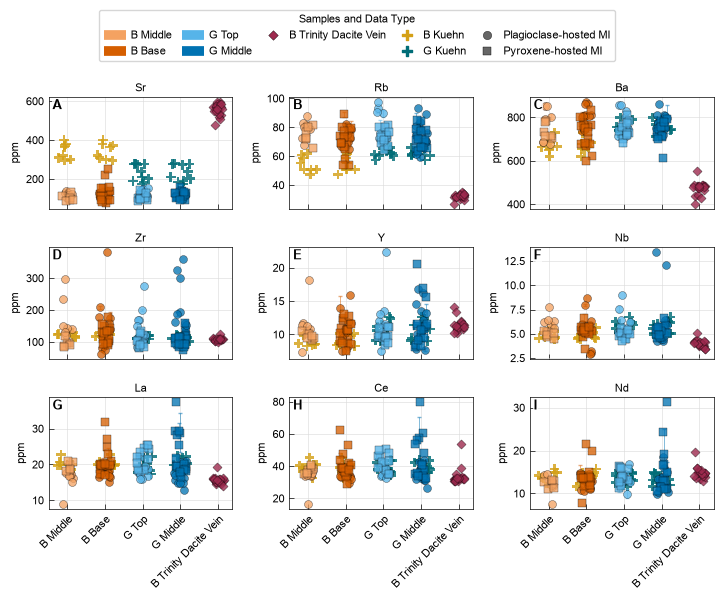

In [3]:
random_generator = np.random.default_rng(JITTER_SEED)
figure, axes = plt.subplots(3, 3, figsize=(FIGURE_WIDTH_IN, FIGURE_HEIGHT_IN), sharex=True)
axes = np.asarray(axes).ravel()
panel_letters = list('ABCDEFGHI')

for panel_index, (axis, element) in enumerate(zip(axes, PLOT_ELEMENTS)):
    mi_element = mi.dropna(subset=[element]).copy()
    for sample, color in SAMPLE_COLORS.items():
        for phase in ['plag', 'pxy']:
            subset = mi_element.loc[mi_element['sample_key'].eq(sample) & mi_element['phase_key'].eq(phase)]
            if subset.empty:
                continue
            x_values = SAMPLE_X[sample] + random_generator.uniform(-0.16, 0.16, len(subset))
            y_errors = pd.to_numeric(subset[f'{element}_std_1sigma'], errors='coerce')
            if y_errors.notna().any():
                axis.errorbar(x_values, subset[element], yerr=y_errors, fmt='none', ecolor=color, elinewidth=0.65, capsize=1.6, alpha=0.52, zorder=2.5)
            axis.scatter(x_values, subset[element], color=color, alpha=0.76, zorder=3, **SCATTER_STYLES[phase])

    dacite_subset = dacite.dropna(subset=[element])
    x_values = SAMPLE_X['B_Dacite_Vein'] + random_generator.uniform(-0.16, 0.16, len(dacite_subset))
    axis.scatter(x_values, dacite_subset[element], color=DACITE_COLOR, alpha=0.80, zorder=3, **SCATTER_STYLES['dacite_vein'])

    for tephra, target_samples in TEPHRA_SAMPLES.items():
        values = kuehn_retained.loc[kuehn_retained['Tephra'].eq(tephra), element].dropna()
        for sample in target_samples:
            x_values = SAMPLE_X[sample] + random_generator.uniform(-0.27, 0.27, len(values))
            axis.scatter(x_values, values, color=KUEHN_COLORS[tephra], alpha=0.82, zorder=2, **SCATTER_STYLES['kuehn_glass'])

    axis.set_title(element, pad=4)
    axis.set_ylabel('ppm')
    axis.grid(True, color='#D9D9D9', linewidth=0.4)
    axis.set_axisbelow(True)
    axis.set_xticks(range(len(ORDERED_SAMPLES)))
    axis.text(0.02, 0.98, panel_letters[panel_index], transform=axis.transAxes, ha='left', va='top', fontsize=PANEL_LABEL_SIZE_PT, fontweight='bold', bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.80, 'pad': 0.3}, zorder=10)
    for spine in axis.spines.values():
        spine.set_visible(True)
    if panel_index < 6:
        axis.tick_params(axis='x', labelbottom=False)
    else:
        axis.set_xticklabels(GROUP_LABELS, rotation=45, ha='right', rotation_mode='anchor')

sample_handles = [
    Line2D([0, 1], [0, 0], color=SAMPLE_COLORS[sample], linewidth=7, solid_capstyle='butt', label=SAMPLE_LABELS[sample]) for sample in ['74D', '74A', '75', '76A']
]
sample_handles += [
    Line2D([], [], linestyle='none', marker=MARKER_PATHS['dacite_vein'], markerfacecolor=DACITE_COLOR, markeredgecolor='black', markeredgewidth=MINIMUM_LINE_WIDTH_PT, markersize=MARKER_SPANS_PT['dacite_vein'], label=DACITE_LABEL),
    Line2D([], [], linestyle='none', marker='', color='none', label=' '),
]
sample_handles += [
    Line2D([], [], linestyle='none', marker=MARKER_PATHS['kuehn_glass'], color=KUEHN_COLORS['B'], markersize=MARKER_SPANS_PT['kuehn_glass'], label='B Kuehn'),
    Line2D([], [], linestyle='none', marker=MARKER_PATHS['kuehn_glass'], color=KUEHN_COLORS['G'], markersize=MARKER_SPANS_PT['kuehn_glass'], label='G Kuehn'),
]
data_type_handles = [
    Line2D([], [], linestyle='none', marker=MARKER_PATHS['plag'], markerfacecolor='#666666', markeredgecolor='black', markeredgewidth=MINIMUM_LINE_WIDTH_PT, markersize=MARKER_SPANS_PT['plag'], label='Plagioclase-hosted MI'),
    Line2D([], [], linestyle='none', marker=MARKER_PATHS['pxy'], markerfacecolor='#666666', markeredgecolor='black', markeredgewidth=MINIMUM_LINE_WIDTH_PT, markersize=MARKER_SPANS_PT['pxy'], label='Pyroxene-hosted MI'),
]
legend_handles = sample_handles + data_type_handles
figure.legend(handles=legend_handles, title='Samples and Data Type', loc='upper center', bbox_to_anchor=(0.5, 0.94), ncol=5, frameon=True, handletextpad=0.45, columnspacing=0.90, labelspacing=0.50)
figure.subplots_adjust(left=0.075, right=0.992, bottom=0.175, top=0.80, wspace=0.31, hspace=0.34)

pdf_path = OUTPUT_DIRECTORY / 'Figure_S13_Trace_Element_Distributions.pdf'
png_path = OUTPUT_DIRECTORY / 'Figure_S13_Trace_Element_Distributions.png'
svg_path = OUTPUT_DIRECTORY / 'Figure_S13_Trace_Element_Distributions.svg'
figure.savefig(pdf_path, format='pdf', facecolor='white', transparent=False)
figure.savefig(png_path, format='png', dpi=EXPORT_DPI, facecolor='white', transparent=False)
figure.savefig(svg_path, format='svg', facecolor='white', transparent=False)
print('Saved:', pdf_path)
print('Saved:', png_path)
print('Saved:', svg_path)
plt.show()